# QA Pipeline Walkthrough — watch the calculations happen

This notebook re-derives, step by step, how the QA triage pipeline turns real
satellite files into a pass / retry / hold / re-task / escalate decision — a deterministic
rules engine (`agent/qa_rules.py`), not an LLM or anything making judgment
calls. **Everything runs on the real scenes in `data/`** — the numbers you
see are the same numbers in `agent/decisions.json`.

Run each cell top to bottom. Cells that compute something print the
intermediate steps so you can see *where* every number comes from. At the end
you get to change a QA threshold and watch the decision flip.

> Kernel: use the repo's virtualenv — `python3 -m venv .venv`, then
> `.venv/bin/pip install -r agent/requirements.txt jupyterlab matplotlib ipywidgets`,
> then launch with `.venv/bin/jupyter lab` from the repo root.

## Setup — imports and scene discovery

This cell just wires up paths and lists the real scenes. `ROOT` is detected so
it works whether Jupyter was launched from the repo root or from `notebooks/`.

In [1]:
import json, sys
from pathlib import Path
import numpy as np
import tifffile
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams["figure.dpi"] = 90

# Locate the repo root (works from repo root or from notebooks/)
ROOT = Path.cwd()
if not (ROOT / "agent").exists() and (ROOT.parent / "agent").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "agent"))   # so we can import the QA engine's own modules later

DATA = ROOT / "data"
scenes = sorted(p for p in DATA.iterdir() if (p / "stac_metadata.json").exists())
print("Real scenes found in data/:")
for p in scenes:
    print(f"  - {p.name}")
print(f"\nWe'll start with the interesting one: {scenes[1].name}")

Real scenes found in data/:
  - 01-clean-cropfield-australia
  - 02-wildfire-smoke-saskatchewan
  - 03-copper-mine-chile

We'll start with the interesting one: 02-wildfire-smoke-saskatchewan


## Look at one scene's files

Each scene folder holds the delivered product: the catalog record
(`stac_metadata.json`), human previews (PNGs), and the two **raster masks**
that QA actually reads. Note how small the masks are compared to the preview:
they are per-pixel *labels*, not images.

In [2]:
scene = scenes[1]   # the wildfire-smoke scene
print(scene.name)
for f in sorted(scene.iterdir()):
    print(f"  {f.name:34s} {f.stat().st_size/1024:9.1f} KB")

02-wildfire-smoke-saskatchewan
  data_mask.tiff                        1749.1 KB
  data_mask_preview.png                   30.2 KB
  pixel_quality_mask.tiff               3532.2 KB
  preview.png                           7490.2 KB
  preview_web.jpg                        319.3 KB
  quality_mask_preview.png                 5.5 KB
  stac_metadata.json                      52.1 KB
  thumbnail.png                          562.5 KB
  thumbnail_web.jpg                       50.0 KB


## The data mask — 4 layers of yes/no

`data_mask.tiff` is one raster with **4 bands**, in Wyvern's fixed order:

| band | question | 1 = | 0 = | 255 = |
|---|---|---|---|---|
| 0 | clear? | clear pixel | not clear | NoData |
| 1 | cloud? | cloudy | not cloudy | NoData |
| 2 | haze? | hazy / smoky | not hazy | NoData |
| 3 | cloud-shadow? | shadowed | not shadowed | NoData |

Let's load it and look at the raw numbers.

In [3]:
dm = tifffile.imread(str(scene / "data_mask.tiff"))
print("data mask shape (H, W, B):", dm.shape, " dtype:", dm.dtype)
print("all unique values in the file:", np.unique(dm))
print()
print("band 1 (cloud) — pixel counts per value:")
vals, counts = np.unique(dm[..., 1], return_counts=True)
for v, c in zip(vals, counts):
    print(f"  value {v:3d}: {c:>12,} pixels  ({100*c/dm[..., 1].size:.2f}% of raster)")

data mask shape (H, W, B): (10352, 6719, 4)  dtype: uint8


all unique values in the file: [  0   1 255]

band 1 (cloud) — pixel counts per value:


  value   0:   25,920,085 pixels  (37.27% of raster)
  value   1:   15,785,025 pixels  (22.69% of raster)
  value 255:   27,849,978 pixels  (40.04% of raster)


---
## Seeing the 4 layers in 3D

The table of counts above is correct but abstract. Plotting `(row, column)` as
the base plane and layer index as height turns "4 fixed condition layers" into
something you can actually see: clear / cloud / haze / cloud-shadow each become
their own flat shape, stacked at different heights, all describing the *same*
scene from a different angle.


/var/folders/8n/bgsjrzs53cq41sdmxxq8k6r80000gn/T/ipykernel_11255/726030631.py:26: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


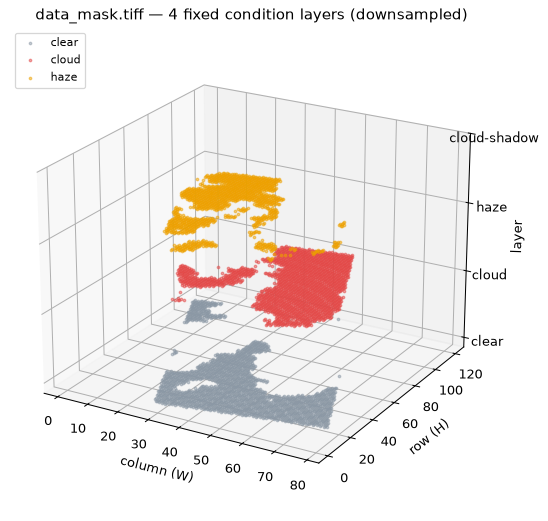

In [4]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (registers 3d projection)

f3d = max(1, dm.shape[0] // 120)
dm_small = dm[::f3d, ::f3d, :]
H3, W3, B3 = dm_small.shape

labels3 = ["clear", "cloud", "haze", "cloud-shadow"]
colors3 = ["#8b98a5", "#e34948", "#eda100", "#2a78d6"]

yy3, xx3 = np.meshgrid(np.arange(H3), np.arange(W3), indexing="ij")

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
for b in range(B3):
    present = dm_small[:, :, b] == 1
    if not present.any():
        continue
    ax.scatter(xx3[present], yy3[present], np.full(present.sum(), b),
               c=colors3[b], s=4, alpha=0.5, label=labels3[b], depthshade=False)

ax.set_xlabel("column (W)"); ax.set_ylabel("row (H)"); ax.set_zlabel("layer")
ax.set_zticks(range(B3)); ax.set_zticklabels(labels3)
ax.set_title("data_mask.tiff — 4 fixed condition layers (downsampled)")
ax.legend(loc="upper left", fontsize=9)
ax.view_init(elev=22, azim=-60)
plt.tight_layout(); plt.show()

## The key preprocessing step: the "valid footprint"

The raster is a rectangle, but the scene inside is an angled strip — the rest
is a `255` NoData border (you can see it below as the black border). **Every
QA percentage is computed over the valid footprint only**, so the empty border
can't dilute the numbers. Watch how much of the raster is empty:

raster pixels:          69,555,088
valid footprint:        41,705,110  (59.96% of raster)
empty 255 border:       27,849,978

→ all percentages below use 41,705,110 as the denominator.


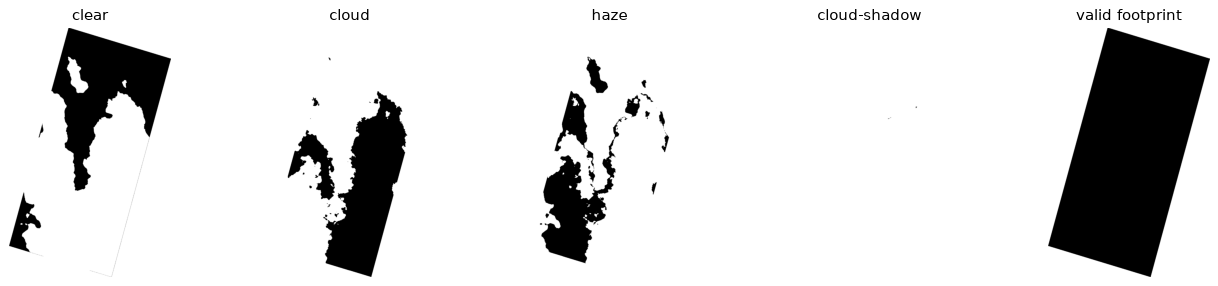

In [5]:
valid = np.any(dm != 255, axis=-1)      # pixel is scene if ANY layer has data
vtot = int(valid.sum())
print(f"raster pixels:        {valid.size:>12,}")
print(f"valid footprint:      {vtot:>12,}  ({100*vtot/valid.size:.2f}% of raster)")
print(f"empty 255 border:     {valid.size - vtot:>12,}")
print(f"\n→ all percentages below use {vtot:,} as the denominator.")

fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
titles = ["clear", "cloud", "haze", "cloud-shadow", "valid footprint"]
for i, ax in enumerate(axes[:4]):
    ax.imshow(dm[::8, ::8, i] == 1, cmap="gray_r"); ax.set_title(titles[i]); ax.axis("off")
axes[4].imshow(valid[::8, ::8], cmap="gray_r"); axes[4].set_title(titles[4]); axes[4].axis("off")
plt.show()

---
## Metric 1 — `band_count`

The pixel quality mask has **one layer per spectral band**, so its depth is
the scene's band count. (We also cross-check it against the STAC catalog's
band list.)

In [6]:
pq = tifffile.imread(str(scene / "pixel_quality_mask.tiff"))
print("PQ mask shape (H, W, B):", pq.shape)
band_count = pq.shape[2]
print(f"→ band_count = {band_count}")

meta = json.loads((scene / "stac_metadata.json").read_text())
platform = meta["properties"]["platform"]
stac_bands = len(meta["assets"]["Cloud optimized GeoTiff"]["eo:bands"])
print(f"platform: {platform} | STAC catalog lists {stac_bands} bands")
rules_cfg = json.loads((ROOT / "agent" / "rules.json").read_text())
print(f"expected bands for {platform}: {rules_cfg['platforms'][platform]}")

PQ mask shape (H, W, B): (10352, 6719, 31)
→ band_count = 31
platform: Dragonette-003 | STAC catalog lists 31 bands
expected bands for Dragonette-003: {'expected_bands': 31}


---
## Metric 2 — `cloud_or_haze_pct` (the interesting one)

Cloud and haze/smoke both block the surface, so QA counts a pixel as
obstructed if **either** layer flags it. The `|` (OR, union) matters: a pixel
flagged as both cloud and haze is one obstructed pixel — it must count once,
not twice.

cloud pixels:                   15,785,025   37.85% of valid


haze (smoke) pixels:            10,195,868   24.45% of valid
pixels flagged as BOTH:                  2   (double-counted by a naive +)
cloud OR haze (union):          25,980,891   62.30% of valid

→ cloud_or_haze_pct = 62.3%


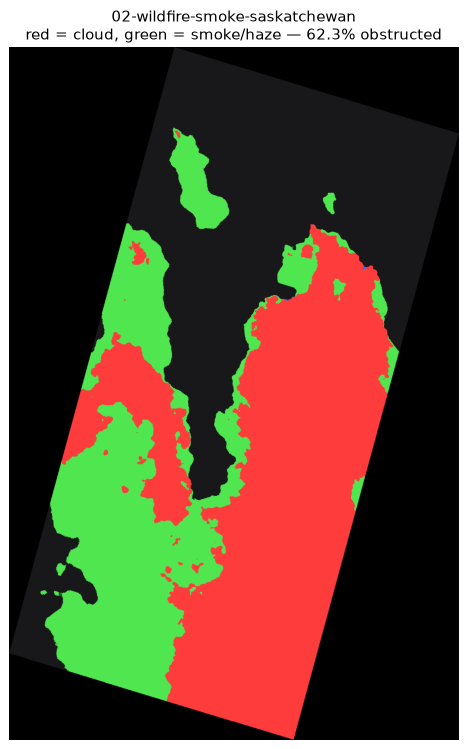

In [7]:
cloud = (dm[..., 1] == 1) & valid
haze  = (dm[..., 2] == 1) & valid
union = cloud | haze
overlap = cloud & haze

print(f"cloud pixels:                 {cloud.sum():>12,}   {100*cloud.sum()/vtot:.2f}% of valid")
print(f"haze (smoke) pixels:          {haze.sum():>12,}   {100*haze.sum()/vtot:.2f}% of valid")
print(f"pixels flagged as BOTH:       {overlap.sum():>12,}   (double-counted by a naive +)")
print(f"cloud OR haze (union):        {union.sum():>12,}   {100*union.sum()/vtot:.2f}% of valid")
cloud_or_haze_pct = round(100 * union.sum() / vtot, 2)
print(f"\n→ cloud_or_haze_pct = {cloud_or_haze_pct}%")

# and the same computation, rendered like the dashboard shows it
def mask_rgb(dm, max_w=1000):
    f = max(1, dm.shape[1] // max_w)
    m = dm[::f, ::f]
    rgb = np.zeros((*m.shape[:2], 3), dtype=np.uint8)
    rgb[m[..., 1] == 1] = (255, 60, 60)     # cloud
    rgb[m[..., 2] == 1] = (80, 230, 80)     # haze/smoke
    rgb[m[..., 3] == 1] = (70, 100, 255)    # shadow
    rgb[(m[..., 0] == 1) & np.all(m != 255, axis=-1)] = (24, 24, 26)  # clear
    rgb[np.all(m == 255, axis=-1)] = (0, 0, 0)                        # outside scene
    return rgb

plt.figure(figsize=(9, 10))
plt.imshow(mask_rgb(dm)); plt.axis("off")
plt.title(f"{scene.name}\nred = cloud, green = smoke/haze — {cloud_or_haze_pct}% obstructed")
plt.show()

---
## Metric 3 — `quality_mask_coverage_pct`

QA can only certify a scene it can *measure*. This metric asks: of the pixels
that belong to the scene (per the data mask), how many also have a value in
the pixel quality mask? If the quality mask were missing, shifted, or
truncated, this drops below 100% and the scene escalates as `MASK_GAP`.

In [8]:
pq_valid = np.any(pq != 255, axis=-1)      # where the PQ mask has data
overlap = int((valid & pq_valid).sum())
quality_mask_coverage_pct = round(100 * overlap / vtot, 2)
print(f"scene pixels:                    {vtot:>12,}")
print(f"of those, with a PQ-mask value:  {overlap:>12,}")
print(f"→ quality_mask_coverage_pct = {quality_mask_coverage_pct}%")

scene pixels:                      41,705,110
of those, with a PQ-mask value:    41,705,110
→ quality_mask_coverage_pct = 100.0%


---
## Metric 4 — `interpolated_pct` (the subtle one)

The pixel quality mask has **one value per pixel per spectral band** (31 bands
on Dragonette-002/003/004, 23 on Dragonette-001). Wyvern's release notes say
this mask "identifies interpolated pixels in each image band" — pixels filled
in by interpolation where rows of valid pixel values are missing. We read `1`
as the interpolated flag, `0` as not flagged and `255` as outside the scene.
(Wyvern's guide doesn't spell out the values, so that reading is an assumption
— it matches what we see in the data.) The denominator is **pixels × bands**:
we're counting band-pixels, not pixels.

Let's compute it on the Chile mine scene, which has some flagged pixels
(28,871 band-pixels — tiny, but non-zero):


Chile: 36,572,740 valid pixels × 23 bands = 841,173,020 band-pixels
interpolated flags found:  28,871
→ interpolated_pct = 100 × 28,871 / 841,173,020 = 0.0034%


bands with any interpolated pixels: [13, 15, 16]
full-band dropout (a band ~100% interpolated): False



cropped to flagged-pixel bbox (+200px pad): rows 4784:8005, cols 830:5855
heat value range in crop: 0 to 1 bands interpolated per pixel


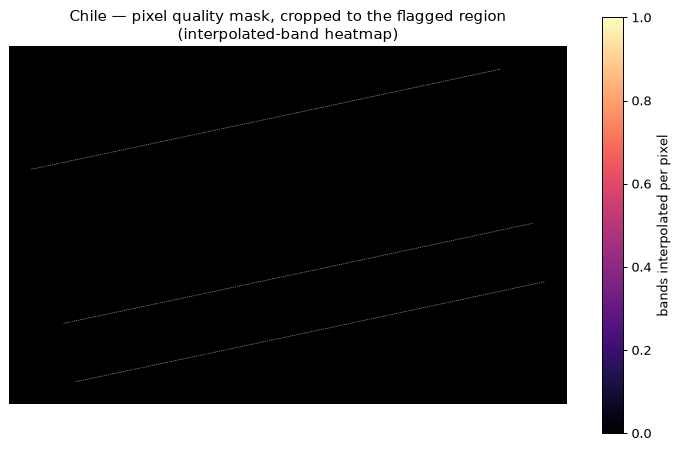

In [9]:
chile = next(p for p in scenes if "copper-mine" in p.name)
dm2 = tifffile.imread(str(chile / "data_mask.tiff"))
pq2 = tifffile.imread(str(chile / "pixel_quality_mask.tiff"))
valid2 = np.any(dm2 != 255, axis=-1)
vtot2 = int(valid2.sum())
nb2 = pq2.shape[2]

interp2 = int((pq2[valid2] == 1).sum())
print(f"Chile: {vtot2:,} valid pixels × {nb2} bands = {vtot2*nb2:,} band-pixels")
print(f"interpolated flags found:  {interp2:,}")
interpolated_pct = round(100 * interp2 / (vtot2 * nb2), 4)
print(f"→ interpolated_pct = 100 × {interp2:,} / {vtot2*nb2:,} = {interpolated_pct}%")

# per-band view — is any single band a full dropout?
per_band = [int((pq2[..., b][valid2] == 1).sum()) for b in range(nb2)]
print(f"bands with any interpolated pixels: {[i for i, c in enumerate(per_band) if c > 0]}")
print(f"full-band dropout (a band ~100% interpolated): {any(c >= vtot2 for c in per_band)}")

# visualize: count interpolated bands per pixel
# Naive full-scene downsampling (stride slicing) makes these flagged pixels invisible: it's a
# thin stripe (~900px tall per band) in a ~9,200px-tall image, across just 3 of 23 bands
# — an every-Nth-pixel stride can skip every single flagged pixel. Two fixes instead:
# 1) crop to the flagged pixels' actual bounding box before downsampling, so nothing is skipped
# 2) cap the colorbar at the real max (heat.max(), which is 1 here: the three stripes sit
#    at different rows, so no pixel is flagged in more than one band), not at 23
bad_rows, bad_cols = np.where((pq2 == 1).any(axis=-1))
pad = 200
r0, r1 = max(0, bad_rows.min() - pad), min(pq2.shape[0], bad_rows.max() + pad)
c0, c1 = max(0, bad_cols.min() - pad), min(pq2.shape[1], bad_cols.max() + pad)
crop = pq2[r0:r1, c0:c1, :]
f = max(1, crop.shape[1] // 1200)
heat = (crop[::f, ::f] == 1).sum(axis=-1)
print(f"\ncropped to flagged-pixel bbox (+{pad}px pad): rows {r0}:{r1}, cols {c0}:{c1}")
print(f"heat value range in crop: {heat.min()} to {heat.max()} bands interpolated per pixel")

plt.figure(figsize=(10, 6))
im = plt.imshow(heat, cmap="magma", vmin=0, vmax=max(1, heat.max()))
plt.colorbar(im, label="bands interpolated per pixel")
plt.title("Chile — pixel quality mask, cropped to the flagged region\n(interpolated-band heatmap)")
plt.axis("off")
plt.show()

---
## Localizing the interpolated pixels

The heatmap above shows *that* some pixels are flagged, but not whether they
are scattered noise or something structured. Let's look at where each affected
band's pixels sit — worth doing before writing an incident note, rather than
only reporting the aggregate `interpolated_pct` number.


---
## Seeing the band-13/15/16 interpolated pixels

Two flat views instead of a 3D plot. **Left:** a top-down map of the scene with
each band's interpolated pixels drawn on it — each band is a thin diagonal stripe,
and the three stripes sit at different rows. **Right:** interpolated pixels per
spectral band — only bands 13, 15 and 16 have any; the other 20 bands have none.


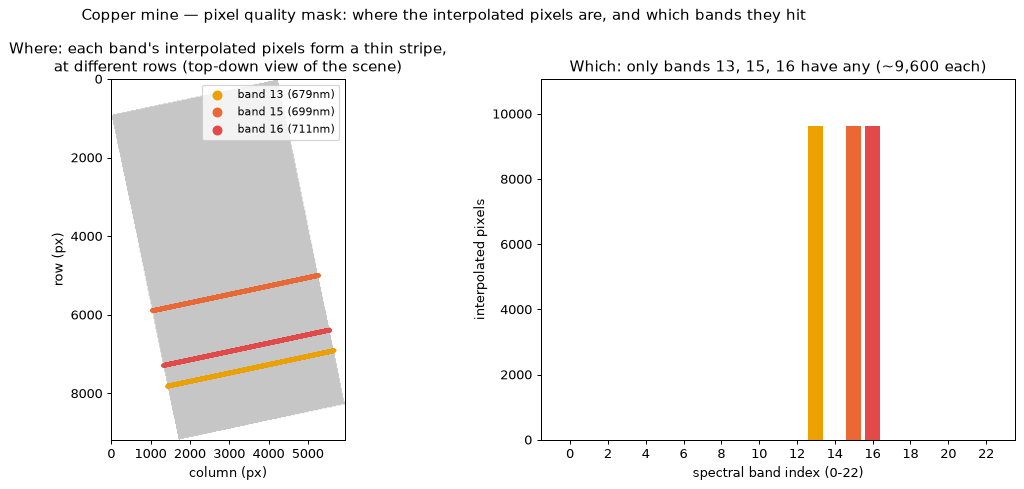

In [10]:
bad_bands = [b for b, c in enumerate(per_band) if c > 0]
# Two flat panels: where the interpolated pixels are, and which bands they hit
band_colors = {13: "#eda100", 15: "#eb6834", 16: "#e34948"}
wl = {13: "679nm", 15: "699nm", 16: "711nm"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.5, 1]})

# left: WHERE — top-down map of the scene footprint with each band's interpolated pixels on top
step = 25
footprint = (pq2[::step, ::step, 0] != 255)
ax1.imshow(footprint, cmap="Greys", vmin=0, vmax=3,
           extent=[0, pq2.shape[1], pq2.shape[0], 0], aspect="equal")
for b in bad_bands:
    r, c = np.where(pq2[..., b] == 1)
    ax1.scatter(c, r, s=3, c=band_colors.get(b, "#e34948"), label=f"band {b} ({wl.get(b, '')})")
ax1.set_xlabel("column (px)"); ax1.set_ylabel("row (px)")
ax1.set_title("Where: each band's interpolated pixels form a thin stripe,\nat different rows (top-down view of the scene)")
ax1.legend(loc="upper right", markerscale=4, fontsize=9)

# right: WHICH — interpolated pixels per spectral band
ax2.bar(range(nb2), per_band, color=[band_colors.get(b, "#c8ccd0") for b in range(nb2)])
ax2.set_xticks(range(0, nb2, 2))
ax2.set_xlabel("spectral band index (0-22)"); ax2.set_ylabel("interpolated pixels")
ax2.set_title("Which: only bands 13, 15, 16 have any (~9,600 each)")
ax2.set_ylim(0, max(per_band) * 1.15)

fig.suptitle("Copper mine — pixel quality mask: where the interpolated pixels are, and which bands they hit", fontsize=12)
plt.tight_layout(); plt.show()


---
## The exact numbers

`% of height` is how far each stripe climbs, as a share of the raster height —
not how much of the image it covers. The stripes are thin, so the covered area
is tiny (0.0034% of all values). The last column shows each stripe's two ends
sitting right on the edge of the scene (a gap of 0 px): every stripe runs the
full width of the scan strip, edge to edge. They look shorter than the raster
only because the scene is a tilted strip with empty corners.

Each band is one diagonal stripe, and the three sit at different rows — not
scattered noise. That is consistent with Wyvern's description of interpolating
missing rows of pixels, i.e. a full scan line missing per band, but we haven't
confirmed that is the cause.


In [11]:
# Exact positions of each band's stripe, and whether it reaches the scene's edges
H, W = pq2.shape[:2]
scene = pq2[..., 0] != 255        # band 0 has data wherever the scene is (the strip, not the empty corners)
print(f"{'band':>4} {'pixels':>7}  {'rows':>13} {'% of height':>12}  {'gap to scene edge (left / right)':>34}")
for b in bad_bands:
    rb, cb = np.where(pq2[:, :, b] == 1)
    li, ri = cb.argmin(), cb.argmax()
    left_gap = cb[li] - np.where(scene[rb[li]])[0].min()
    right_gap = np.where(scene[rb[ri]])[0].max() - cb[ri]
    print(f"{b:>4} {per_band[b]:>7,}  {rb.min():>5,}-{rb.max():<6,} {100*(rb.max()-rb.min())/H:>11.0f}%  "
          f"{left_gap:>14} px / {right_gap} px")
rows = np.where((pq2[:, :, bad_bands] == 1).any(axis=(1, 2)))[0]
print(f"\nall three bands together: rows {rows.min():,}-{rows.max():,} ({100*(rows.max()-rows.min())/H:.0f}% of image height)")


band  pixels           rows  % of height    gap to scene edge (left / right)


  13   9,620  6,901-7,805           10%               0 px / 0 px


  15   9,626  4,984-5,889           10%               0 px / 0 px


  16   9,625  6,375-7,279           10%               0 px / 0 px



all three bands together: rows 4,984-7,805 (31% of image height)


---
## Interpolated pixels at true scale

One bar for every band-pixel in the scene that isn't flagged, one for the
interpolated (flagged) ones, on the same linear scale. The interpolated bar is
too small to see — that is the true proportion.


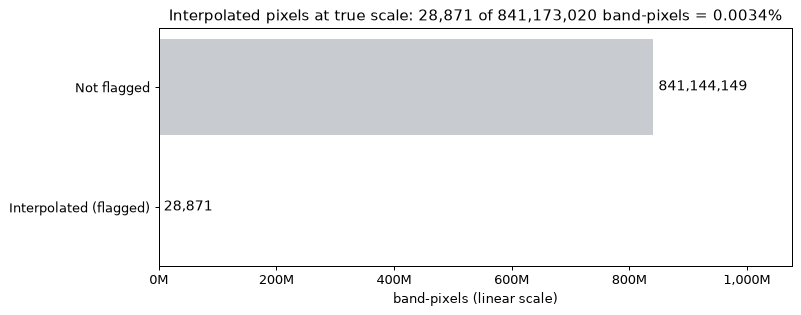

In [12]:
# true scale: interpolated vs not-flagged band-pixels, same linear axis
import matplotlib.ticker as mticker

total = int(valid2.sum()) * nb2
interp = int((pq2[valid2] == 1).sum())
unflagged = total - interp

fig, ax = plt.subplots(figsize=(9, 3.6))
vals = [unflagged, interp]
bars = ax.barh(["Not flagged", "Interpolated (flagged)"], vals, color=["#c8ccd0", "#e34948"])
ax.invert_yaxis()
ax.set_xlim(0, total * 1.28)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v/1e6:,.0f}M"))
ax.set_xlabel("band-pixels (linear scale)")
for bar, v in zip(bars, vals):
    ax.text(v + total * 0.01, bar.get_y() + bar.get_height() / 2, f"{v:,}", va="center", fontsize=11)
ax.set_title(f"Interpolated pixels at true scale: {interp:,} of {total:,} band-pixels = {100*interp/total:.4f}%", fontsize=12)
plt.tight_layout(); plt.show()


---
## All four metrics for all three scenes

Now run the same four calculations over every scene and compare. These are the
same metrics `analyze_scene.py` computes, which `qa_rules.py` then evaluates.

In [13]:
def metrics_for(folder):
    d = DATA / folder
    dm_ = tifffile.imread(str(d / "data_mask.tiff"))
    pq_ = tifffile.imread(str(d / "pixel_quality_mask.tiff"))
    v_ = np.any(dm_ != 255, axis=-1); vt = int(v_.sum())
    cl = (dm_[..., 1] == 1) & v_; hz = (dm_[..., 2] == 1) & v_
    pqv = np.any(pq_ != 255, axis=-1)
    return {
        "bands": pq_.shape[2],
        "cloud_or_haze_pct": round(100 * (cl | hz).sum() / vt, 2),
        "mask_cov_pct": round(100 * (v_ & pqv).sum() / vt, 2),
        "interp_pct": round(100 * (pq_[v_] == 1).sum() / (vt * pq_.shape[2]), 4),
        "valid_pct": round(100 * vt / v_.size, 2),
    }

print(f"{'scene':<40s} {'bands':>5s} {'cloud+haze%':>11s} {'maskcov%':>8s} {'interp%':>8s} {'valid%':>6s}")
for p in scenes:
    m = metrics_for(p.name)
    print(f"{p.name:<40s} {m['bands']:>5d} {m['cloud_or_haze_pct']:>11.2f} {m['mask_cov_pct']:>8.2f} {m['interp_pct']:>8.4f} {m['valid_pct']:>6.2f}")

scene                                    bands cloud+haze% maskcov%  interp% valid%


01-clean-cropfield-australia                31        0.00   100.00   0.0000  47.05


02-wildfire-smoke-saskatchewan              31       62.30   100.00   0.0000  59.96


03-copper-mine-chile                        23        0.00   100.00   0.0034  67.10


---
## The rules — `agent/rules.json`

The thresholds aren't hardcoded in the engine: `qa_rules.py` reads the PRD's
rules from `rules.json`. Notice the shape of every rule — `levels` (which processing
level it applies to), `category`, `routing` (retry, hold, re-task or escalate), and
mechanical `checks` (metric + operator + threshold). QA-3's checks carry their
own `routing` — the first failing one wins — and prefer AOI cloud, falling back
to scene-wide (`fallback_metric`) when no AOI exists.

In [14]:
rules = json.loads((ROOT / "agent" / "rules.json").read_text())
print("max_retries:", rules["max_retries"])
print("platforms (expected bands):", json.dumps(rules["platforms"]))
print()
for r in rules["rules"]:
    checks = "; ".join(
        f"{c['metric']} {c.get('op','')} {c.get('threshold', c.get('threshold_ref'))}"
        + (f" → {c['routing']}" if "routing" in c else "")
        for c in r["checks"]
    )
    print(f"{r['id']:5s} [{','.join(r['levels']):10s}] {r['category']:10s} → {r['routing']:8s} | {checks}")

max_retries: 2
platforms (expected bands): {"Dragonette-001": {"expected_bands": 23}, "Dragonette-002": {"expected_bands": 31}, "Dragonette-003": {"expected_bands": 31}, "Dragonette-004": {"expected_bands": 31}}

QA-1  [L1B       ] INCOMPLETE → escalate | band_count lt platform.expected_bands; aoi_coverage_pct lt 95
QA-2  [L1B,L2A   ] MASK_GAP   → escalate | quality_mask_coverage_pct lt 100
QA-3  [L1B,L2A   ] CLOUD      → hold     | aoi_cloud_or_haze_pct gt 80 → retask; aoi_cloud_or_haze_pct gt 40 → hold
QA-4  [L1B,L2A   ] SENSOR     → escalate | interpolated_pct gt 2; full_band_dropout eq True; max_high_value_band_interpolated_pct gt 0.1
QA-5  [L1B,L2A   ] GEOM       → retry    | geolocation_rmse_px gt 1; coreg_offset_px gt 0.5
QA-6  [L2A       ] RADIO      → retry    | reflectance_out_of_bounds_pct gt 0.5
QA-7  [L2A       ] RADIO      → escalate | band_corr_mean lt 0.7; band_corr_min_tile lt 0.5


---
## Run the *real* QA engine and verify

Now we hand our metrics to the same modules the pipeline actually runs
(`analyze_scene.py` → `qa_rules.py`) and check the decisions match what's
already committed in `agent/decisions.json`.

In [15]:
from analyze_scene import compute_metrics
from qa_rules import evaluate_rule, decide

payload = json.loads((ROOT / "agent" / "decisions.json").read_text())
expected = {s["scene_id"]: s["decision"] for s in payload["scenes"]}

for p in scenes:
    info, metrics = compute_metrics(p)
    platform = rules["platforms"].get(info["platform"], {})
    scene = {"processing_level": info["processing_level"], "platform_spec": platform,
             "retry_count": 0, "max_retries": rules["max_retries"], "superseded": False}
    evals = [evaluate_rule(r, metrics, scene) for r in rules["rules"]]
    dec = decide(evals, metrics, scene)
    match = "✓ matches decisions.json" if dec["decision"] == expected.get(info["scene_id"]) else "✗ MISMATCH"
    print(info["scene_id"])
    print(f"  → {dec['decision'].upper():9s} category={dec['failure_category']} rule={dec['fired_rule']} "
          f"retries={dec['retry_count']}   {match}")
    print(f"  reasoning: {dec['reasoning']}")
    print()

wyvern_dragonette-003_20250319T000402_d5ebab06_l2a
  → PASS      category=None rule=None retries=0   ✓ matches decisions.json
  reasoning: No QA rule failed. Scene is CLEAN.



wyvern_dragonette-003_20250531T173810_56fca26e_l2a
  → HOLD      category=CLOUD rule=QA-3 retries=0   ✓ matches decisions.json
  reasoning: Rule QA-3 (cloud_obstruction) fired: cloud_or_haze_pct=62.3 gt threshold=40 → FAIL



wyvern_dragonette-001_20240620T145630_2d5d0eef_l2a
  → PASS      category=None rule=None retries=0   ✓ matches decisions.json
  reasoning: No QA rule failed. Scene is CLEAN.



---
## Why QA-4 and QA-7 also check individual bands and tiles

Recall the interpolated stripes found earlier (bands 13/15/16 = 679/699/711nm).
A scene-wide average can hide a problem like that: QA-7's `band_corr_mean`
(0.969) is one number for the whole scene, so a thin stripe barely moves it.
That's why both rules carry a second, narrower condition alongside their
scene-wide one (see `rules.json` above, and PRD §3):

1. **QA-4** checks the worst single *red-edge* band (711–782nm) against a
   stricter ceiling (0.1%, vs. 2% scene-wide) — the PRD treats the red edge as
   the high-value range, so flagged pixels concentrated there are held to a tighter
   bar than the same number of flagged pixels spread thin across all bands.
2. **QA-7** checks the worst of an 8×8 spatial-tile grid against a looser
   threshold (0.5, vs. 0.7 scene-wide) — a small tile's naturally noisier
   estimate isn't held to the scene-wide bar, but a badly inconsistent tile
   still gets caught.
3. **Delivery-readiness** can reach `delivery_ready_partial`: ship with
   specific affected bands excluded, rather than holding back the whole
   scene for flagged pixels in a few of its 23 bands. Strictly opt-in, and only when
   QA-4's per-band condition is the *sole* failure — QA-3/5/6/7 failures aren't
   confined to specific bands, so there's nothing to partially exclude.

`compute_metrics()`/`qa_rules.py` already implement all three — the cell
above ("Run the real QA engine") is already running this logic. Let's look
at the metrics directly for the copper-mine scene.


In [16]:
chile_info, chile_metrics = compute_metrics(chile)

print("QA-4 — sensor artifact (PRD §3):")
print(f"  interpolated_pct (scene-wide):            {chile_metrics['interpolated_pct']}%  (threshold 2%)")
print(f"  max_high_value_band_interpolated_pct:     {chile_metrics['max_high_value_band_interpolated_pct']}%  (threshold 0.1%, red-edge bands only)")
print("  → band 16 (711nm) is the only affected red-edge band, and its 0.0263% is well\n"
      "    under the 0.1% per-band ceiling, so this scene passes QA-4.\n")

chile_platform = rules["platforms"].get(chile_info["platform"], {})
chile_scene = {"processing_level": chile_info["processing_level"], "platform_spec": chile_platform,
               "retry_count": 0, "max_retries": rules["max_retries"], "superseded": False,
               "partial_delivery_opt_in": False}
chile_evals = [evaluate_rule(r, chile_metrics, chile_scene) for r in rules["rules"]]
chile_dec = decide(chile_evals, chile_metrics, chile_scene)

print("Delivery-readiness fields (PRD §5):")
print(f"  delivery_ready:         {chile_dec['delivery_ready']}")
print(f"  delivery_ready_partial: {chile_dec['delivery_ready_partial']}")
print(f"  excluded_bands:         {chile_dec['excluded_bands']}")
print(f"  note: {chile_dec['delivery_ready_note']}")
print("  → this scene passes outright, so partial delivery doesn't engage — it only\n"
      "    applies when QA-4's per-band check is the SOLE failure. Shown here so you\n"
      "    can see the fields exist.")


QA-4 — sensor artifact (PRD §3):
  interpolated_pct (scene-wide):            0.0034%  (threshold 2%)
  max_high_value_band_interpolated_pct:     0.0263%  (threshold 0.1%, red-edge bands only)
  → band 16 (711nm) is the only affected red-edge band, and its 0.0263% is well
    under the 0.1% per-band ceiling, so this scene passes QA-4.

Delivery-readiness fields (PRD §5):
  delivery_ready:         True
  delivery_ready_partial: False
  excluded_bands:         []
  note: Passed on all assessable rules and meets PRD section 5 conditions.
  → this scene passes outright, so partial delivery doesn't engage — it only
    applies when QA-4's per-band check is the SOLE failure. Shown here so you
    can see the fields exist.


---
## Experiment — break the rules, watch the decision flip

The Saskatchewan scene has 62.3% cloud+smoke. QA-3's hold threshold is 40%, so
it's held for the customer (not reprocessed — reprocessing can't remove cloud;
above 80% it would re-task a new capture). What if the hold threshold were different? **Drag the slider.** This is
the whole job in miniature: someone sets a threshold, the pipeline reacts,
and you have to live with the consequences.

- Drag it **up to 70%**: Saskatchewan now *passes* — we'd ship a scene that is
  62.3% smoke. Why is that dangerous?
- Drag it **down to 20%**: Saskatchewan is still held (62.3% > 20%) — lowering
  the threshold only makes the rule stricter.
- The real lesson: a threshold isn't "correct" in the abstract; it's a
  business decision about how much unusable imagery you're willing to deliver.


In [17]:
from ipywidgets import interact, FloatSlider
import os

sk = next(p for p in scenes if "wildfire" in p.name)
sk_info, sk_metrics = compute_metrics(sk)
sk_scene = {"processing_level": "L2A",
            "platform_spec": rules["platforms"][sk_info["platform"]],
            "retry_count": 0, "max_retries": rules["max_retries"], "superseded": False}

def qa3_experiment(threshold):
    rules2 = json.loads((ROOT / "agent" / "rules.json").read_text())
    for r in rules2["rules"]:
        if r["id"] == "QA-3":
            next(c for c in r["checks"] if c.get("routing") == "hold")["threshold"] = threshold
    evals = [evaluate_rule(r, sk_metrics, sk_scene) for r in rules2["rules"]]
    dec = decide(evals, sk_metrics, sk_scene)
    print(f"Saskatchewan cloud_or_haze = {sk_metrics['cloud_or_haze_pct']}%   |   "
          f"QA-3 hold threshold = {threshold}%")
    print(f"→ decision: {dec['decision'].upper()}   ({dec['reasoning']})")

# The live slider only works in a running Jupyter session (ipywidgets needs a
# comm channel to the frontend) — it hangs headless `jupyter nbconvert --execute`.
# Skip it automatically when running non-interactively; run a few thresholds by
# hand instead so the notebook still shows real output when exported.
if os.environ.get("JPY_PARENT_PID") and not os.environ.get("NBCONVERT_EXECUTE"):
    interact(qa3_experiment, threshold=FloatSlider(min=0, max=90, step=1, value=40,
                                                   description="QA-3 hold %"));
else:
    print("(non-interactive run — showing a few threshold values instead of the live slider)\n")
    for t in [20, 40, 62.3, 70, 90]:
        qa3_experiment(t)
        print()


(non-interactive run — showing a few threshold values instead of the live slider)

Saskatchewan cloud_or_haze = 62.3%   |   QA-3 hold threshold = 20%
→ decision: HOLD   (Rule QA-3 (cloud_obstruction) fired: cloud_or_haze_pct=62.3 gt threshold=20 → FAIL)

Saskatchewan cloud_or_haze = 62.3%   |   QA-3 hold threshold = 40%
→ decision: HOLD   (Rule QA-3 (cloud_obstruction) fired: cloud_or_haze_pct=62.3 gt threshold=40 → FAIL)

Saskatchewan cloud_or_haze = 62.3%   |   QA-3 hold threshold = 62.3%
→ decision: PASS   (No QA rule failed. Scene is CLEAN.)

Saskatchewan cloud_or_haze = 62.3%   |   QA-3 hold threshold = 70%
→ decision: PASS   (No QA rule failed. Scene is CLEAN.)

Saskatchewan cloud_or_haze = 62.3%   |   QA-3 hold threshold = 90%
→ decision: PASS   (No QA rule failed. Scene is CLEAN.)

